<img src = "https://drive.google.com/uc?export=view&id=1FpwoiW7eC_aEKJ53NReEyrW8qAR3RFs0" alt = "Encabezado MLDS" width = "100%">  </img>

# **Entendimiento del Negocio y Carga de Datos**
---

Este notebook es una plantilla que le puede servir como guía para el primer entregable del proyecto aplicado.

## **0. Integrantes del equipo de trabajo**
---

Por favor incluya los nombres completos y número de identificación de los integrantes del equipo de trabajo:

1. ---**ALEJANDRA JARAMILLO MEJIA**--- 1002652912
2. ---**SANTIAGO CHAPARRO SUZUNAGA**--- 1002760592
3. ---**BRAYAN SEBASTIAN YEPES GARCIA**--- 1015457884

## **1. Marco de Proyecto**
---

Normalmente, se suele construir un marco de proyecto para mostrar los resultados del entendimiento del negocio. Para ello, se debe dar respuesta a los siguientes elementos:

### **1.1. Trasfondo del Negocio**
---

- ¿Quién es el cliente o los beneficiarios del proyecto? ¿En qué dominio se encuentran (marketing, medicina, entre otros)?
- ¿Qué problemas del negocio o del dominio estamos tratando de solucionar?

* ¿Quién es el cliente o los beneficiarios del proyecto? ¿En qué dominio se encuentran (marketing, medicina, entre otros)?

El dominio es la auditoría de procesos electorales, en la intersección entre administración pública y análisis de datos.

Se trata de un proyecto académico, sin un cliente institucional que lo haya encargado. Sin embargo, el problema que aborda pertenece a la función de auditoría electoral. Los datos provienen del paquete que la Registraduría Nacional del Estado Civil publica bajo el nombre *Archivos Básicos para Auditores*, concebido para que terceros puedan verificar el proceso de forma independiente; por eso el usuario natural de la solución es quien realiza esa verificación.

De ahí se desprenden los beneficiarios potenciales:

- Los auditores de sistemas que la Registraduría acredita para cada elección, que son el público natural de estos archivos.
- El Consejo Nacional Electoral, que declara los resultados definitivos y resuelve las reclamaciones.
- Los partidos políticos y sus testigos electorales, que tienen derecho a revisar el escrutinio pero carecen de herramientas para priorizar qué revisar entre más de cien mil mesas.
- La Misión de Observación Electoral y otras organizaciones de sociedad civil que hacen seguimiento al proceso.

Y el beneficiario último es la ciudadanía, en la medida en que la confianza en el sistema electoral depende de que existan mecanismos de verificación efectivos y auditables.

* ¿Qué problemas del negocio o del dominio estamos tratando de solucionar?

El análisis de resultados electorales implica procesar numerosos registros asociados a mesas de votación, candidatos, partidos y ubicaciones geográficas. Identificar manualmente patrones inusuales en estos datos puede resultar complejo, especialmente cuando se requiere comparar mesas dentro de un mismo puesto de votación o examinar diferencias entre distintas fuentes de información.

El problema que aborda este proyecto es la ausencia de un procedimiento analítico automatizado que permita identificar y priorizar mesas cuyos patrones de votación se aparten de los observados en otras mesas comparables. Estas diferencias pueden estar relacionadas con características legítimas del comportamiento electoral, particularidades territoriales, problemas de calidad de los datos u otras circunstancias que requieran un análisis adicional.

Para abordar esta necesidad, se propone un prototipo de aprendizaje automático con tres componentes complementarios: (1) un **clasificador supervisado** que estima la probabilidad de que una mesa presente novedades documentadas en los registros oficiales; (2) un **modelo de regresión supervisada** que estima la magnitud de las discrepancias entre preconteo y escrutinio; y (3) un **detector no supervisado** de mesas con patrones multivariados atípicos. Los tres producen puntuaciones que permiten ordenar las mesas y priorizar cuáles revisar primero.

La solución no pretende determinar automáticamente la existencia de fraude ni atribuir irregularidades a las mesas identificadas. Su propósito es apoyar el análisis exploratorio, facilitar la identificación de patrones poco frecuentes y proporcionar información que contribuya a orientar revisiones posteriores. La utilidad de los resultados dependerá de la calidad de los datos, de la comparabilidad entre las mesas y de la validación estadística de los patrones encontrados.


### **1.2. Alcance**
---


Detección de anomalías electorales mediante aprendizaje automático supervisado y no supervisado: estudio de caso de la primera vuelta de las elecciones presidenciales de Colombia de 2026.

#### Objetivo de negocio

Reducir el esfuerzo de revisión de los auditores y observadores electorales, que hoy deben elegir qué revisar entre más de 122 000 mesas sin un criterio analítico de priorización, ofreciéndoles un ordenamiento de mesas basado en evidencia que concentre en pocas mesas la mayor parte de los casos que ameritan revisión.

#### Objetivo general del proyecto de *machine learning*

Desarrollar y evaluar un prototipo de aprendizaje automático supervisado y no supervisado, utilizando exclusivamente registros electorales oficiales de la primera vuelta presidencial de Colombia de 2026, para clasificar novedades documentadas, modelar discrepancias entre preconteo y escrutinio e identificar patrones estadísticamente atípicos, comparando los resultados con métodos estadísticos de referencia y analizando sus limitaciones como herramienta de apoyo a la auditoría electoral.

#### Objetivos específicos

1. Integrar y validar los registros oficiales de preconteo, escrutinio, novedades y catálogos a nivel de mesa.
2. Caracterizar las mesas mediante análisis exploratorio e indicadores de participación, distribución y concentración del voto, y consistencia entre fuentes.
3. Entrenar y comparar clasificadores (regresión logística, árbol de decisión y Random Forest) que estimen la probabilidad de que una mesa presente novedades documentadas.
4. Entrenar y comparar modelos de regresión (lineal, Random Forest y Gradient Boosting) que estimen la magnitud de la discrepancia entre preconteo y escrutinio.
5. Aplicar Isolation Forest y LOF para asignar a cada mesa una puntuación de atipicidad y producir un listado priorizado.
6. Comparar todos los modelos contra métodos estadísticos de referencia y documentar sus limitaciones e interpretación.



In [ ]:
import base64
from IPython.display import Image, display

def mermaid(codigo):
    b64 = base64.urlsafe_b64encode(codigo.encode("utf-8")).decode("ascii")
    display(Image(url="https://mermaid.ink/img/" + b64))

In [ ]:
!pip install -q diagrams
!apt-get -qq install -y graphviz > /dev/null



#### ¿Qué solución se desea implementar?

Se propone desarrollar un **prototipo académico de análisis de registros electorales mediante técnicas de aprendizaje automático**, orientado a identificar patrones estadísticamente atípicos, clasificar novedades administrativas documentadas y estimar discrepancias entre los resultados de preconteo y escrutinio de la primera vuelta de las elecciones presidenciales de Colombia de 2026.

La solución se implementará utilizando registros electorales oficiales de preconteo, escrutinio, novedades administrativas y catálogos auxiliares. La información se integrará principalmente a nivel de mesa de votación, mediante procedimientos de validación, limpieza, análisis exploratorio e ingeniería de características.

El proyecto comprenderá tres componentes principales de aprendizaje automático:

1. **Clasificación supervisada:** predecir la presencia o ausencia de novedades electorales documentadas mediante regresión logística, árboles de decisión y Random Forest, utilizando etiquetas construidas a partir de registros oficiales.

2. **Regresión supervisada:** estimar la magnitud de las discrepancias observadas entre preconteo y escrutinio mediante modelos de regresión lineal, Random Forest y Gradient Boosting. Se contemplará un enfoque en dos etapas para considerar la elevada proporción de registros sin discrepancias.

3. **Detección no supervisada de anomalías:** identificar mesas de votación con comportamientos estadísticamente atípicos mediante Isolation Forest y Local Outlier Factor (LOF), a partir de indicadores electorales y variables de consistencia.

De manera complementaria, se utilizarán técnicas de **agrupamiento exploratorio**, como K-Means y agrupamiento jerárquico, para caracterizar perfiles de puestos de votación, así como métodos estadísticos robustos que sirvan como referencia para comparar los resultados.

La solución permitirá generar indicadores descriptivos, métricas de evaluación, puntuaciones de atipicidad, visualizaciones y listados de registros que faciliten el análisis comparativo de los diferentes enfoques y la identificación de observaciones que ameriten una revisión adicional.

In [ ]:

mermaid("""
%%{init: {
  "theme": "base",
  "flowchart": {
    "curve": "basis",
    "nodeSpacing": 40,
    "rankSpacing": 60,
    "padding": 20,
    "htmlLabels": true
  },
  "themeVariables": {
    "fontFamily": "Helvetica, Arial, sans-serif",
    "fontSize": "14px",
    "lineColor": "#94A3B8",
    "primaryBorderColor": "#CBD5E1",
    "clusterBkg": "#F8FAFC",
    "clusterBorder": "#E2E8F0"
  }
}}%%

flowchart LR

    %% ============================
    %% ACTOR Y ACCESO
    %% ============================

    A(["Investigador, observador<br/>o analista electoral"])

    B["Ejecución del prototipo<br/>en Jupyter Notebook"]

    %% ============================
    %% EXPLORACIÓN Y ANÁLISIS
    %% ============================

    C["Exploración de indicadores<br/>Clasificación · Regresión · Anomalías"]

    D["Análisis de resultados<br/>Modelos · Mesas priorizadas"]

    %% ============================
    %% VALIDACIÓN E INTERPRETACIÓN
    %% ============================

    E["Contraste de hallazgos<br/>con documentación electoral"]

    F(["Documentación de hallazgos<br/>Explicaciones · Limitaciones"])

    %% ============================
    %% FLUJO DE INTERACCIÓN
    %% ============================

    A --> B --> C --> D --> E --> F

    %% ============================
    %% SISTEMA DE DISEÑO
    %% ============================

    classDef data fill:#EFF6FF,stroke:#3B82F6,stroke-width:1.5px,color:#1E40AF

    classDef finding fill:#FEF3C7,stroke:#D97706,stroke-width:2px,color:#92400E

    classDef decision fill:#FFF7ED,stroke:#F59E0B,stroke-width:1.5px,color:#92400E

    classDef alternative fill:#F8FAFC,stroke:#CBD5E1,stroke-width:1.2px,color:#334155

    classDef validation fill:#ECFDF5,stroke:#10B981,stroke-width:1.5px,color:#065F46

    classDef warning fill:#FFF1F2,stroke:#E11D48,stroke-width:2px,color:#9F1239

    %% ============================
    %% ESTILOS COMPLEMENTARIOS
    %% ============================

    classDef actor fill:#FFFFFF,stroke:#3B82F6,stroke-width:2px,color:#1E40AF

    classDef output fill:#DBEAFE,stroke:#2563EB,stroke-width:2px,color:#1E3A8A

    %% ============================
    %% ASIGNACIÓN DE ESTILOS
    %% ============================

    class A actor
    class B,C data
    class D finding
    class E validation
    class F output

    %% ============================
    %% CONECTORES
    %% ============================

    linkStyle default stroke:#94A3B8,stroke-width:1.5px
""")


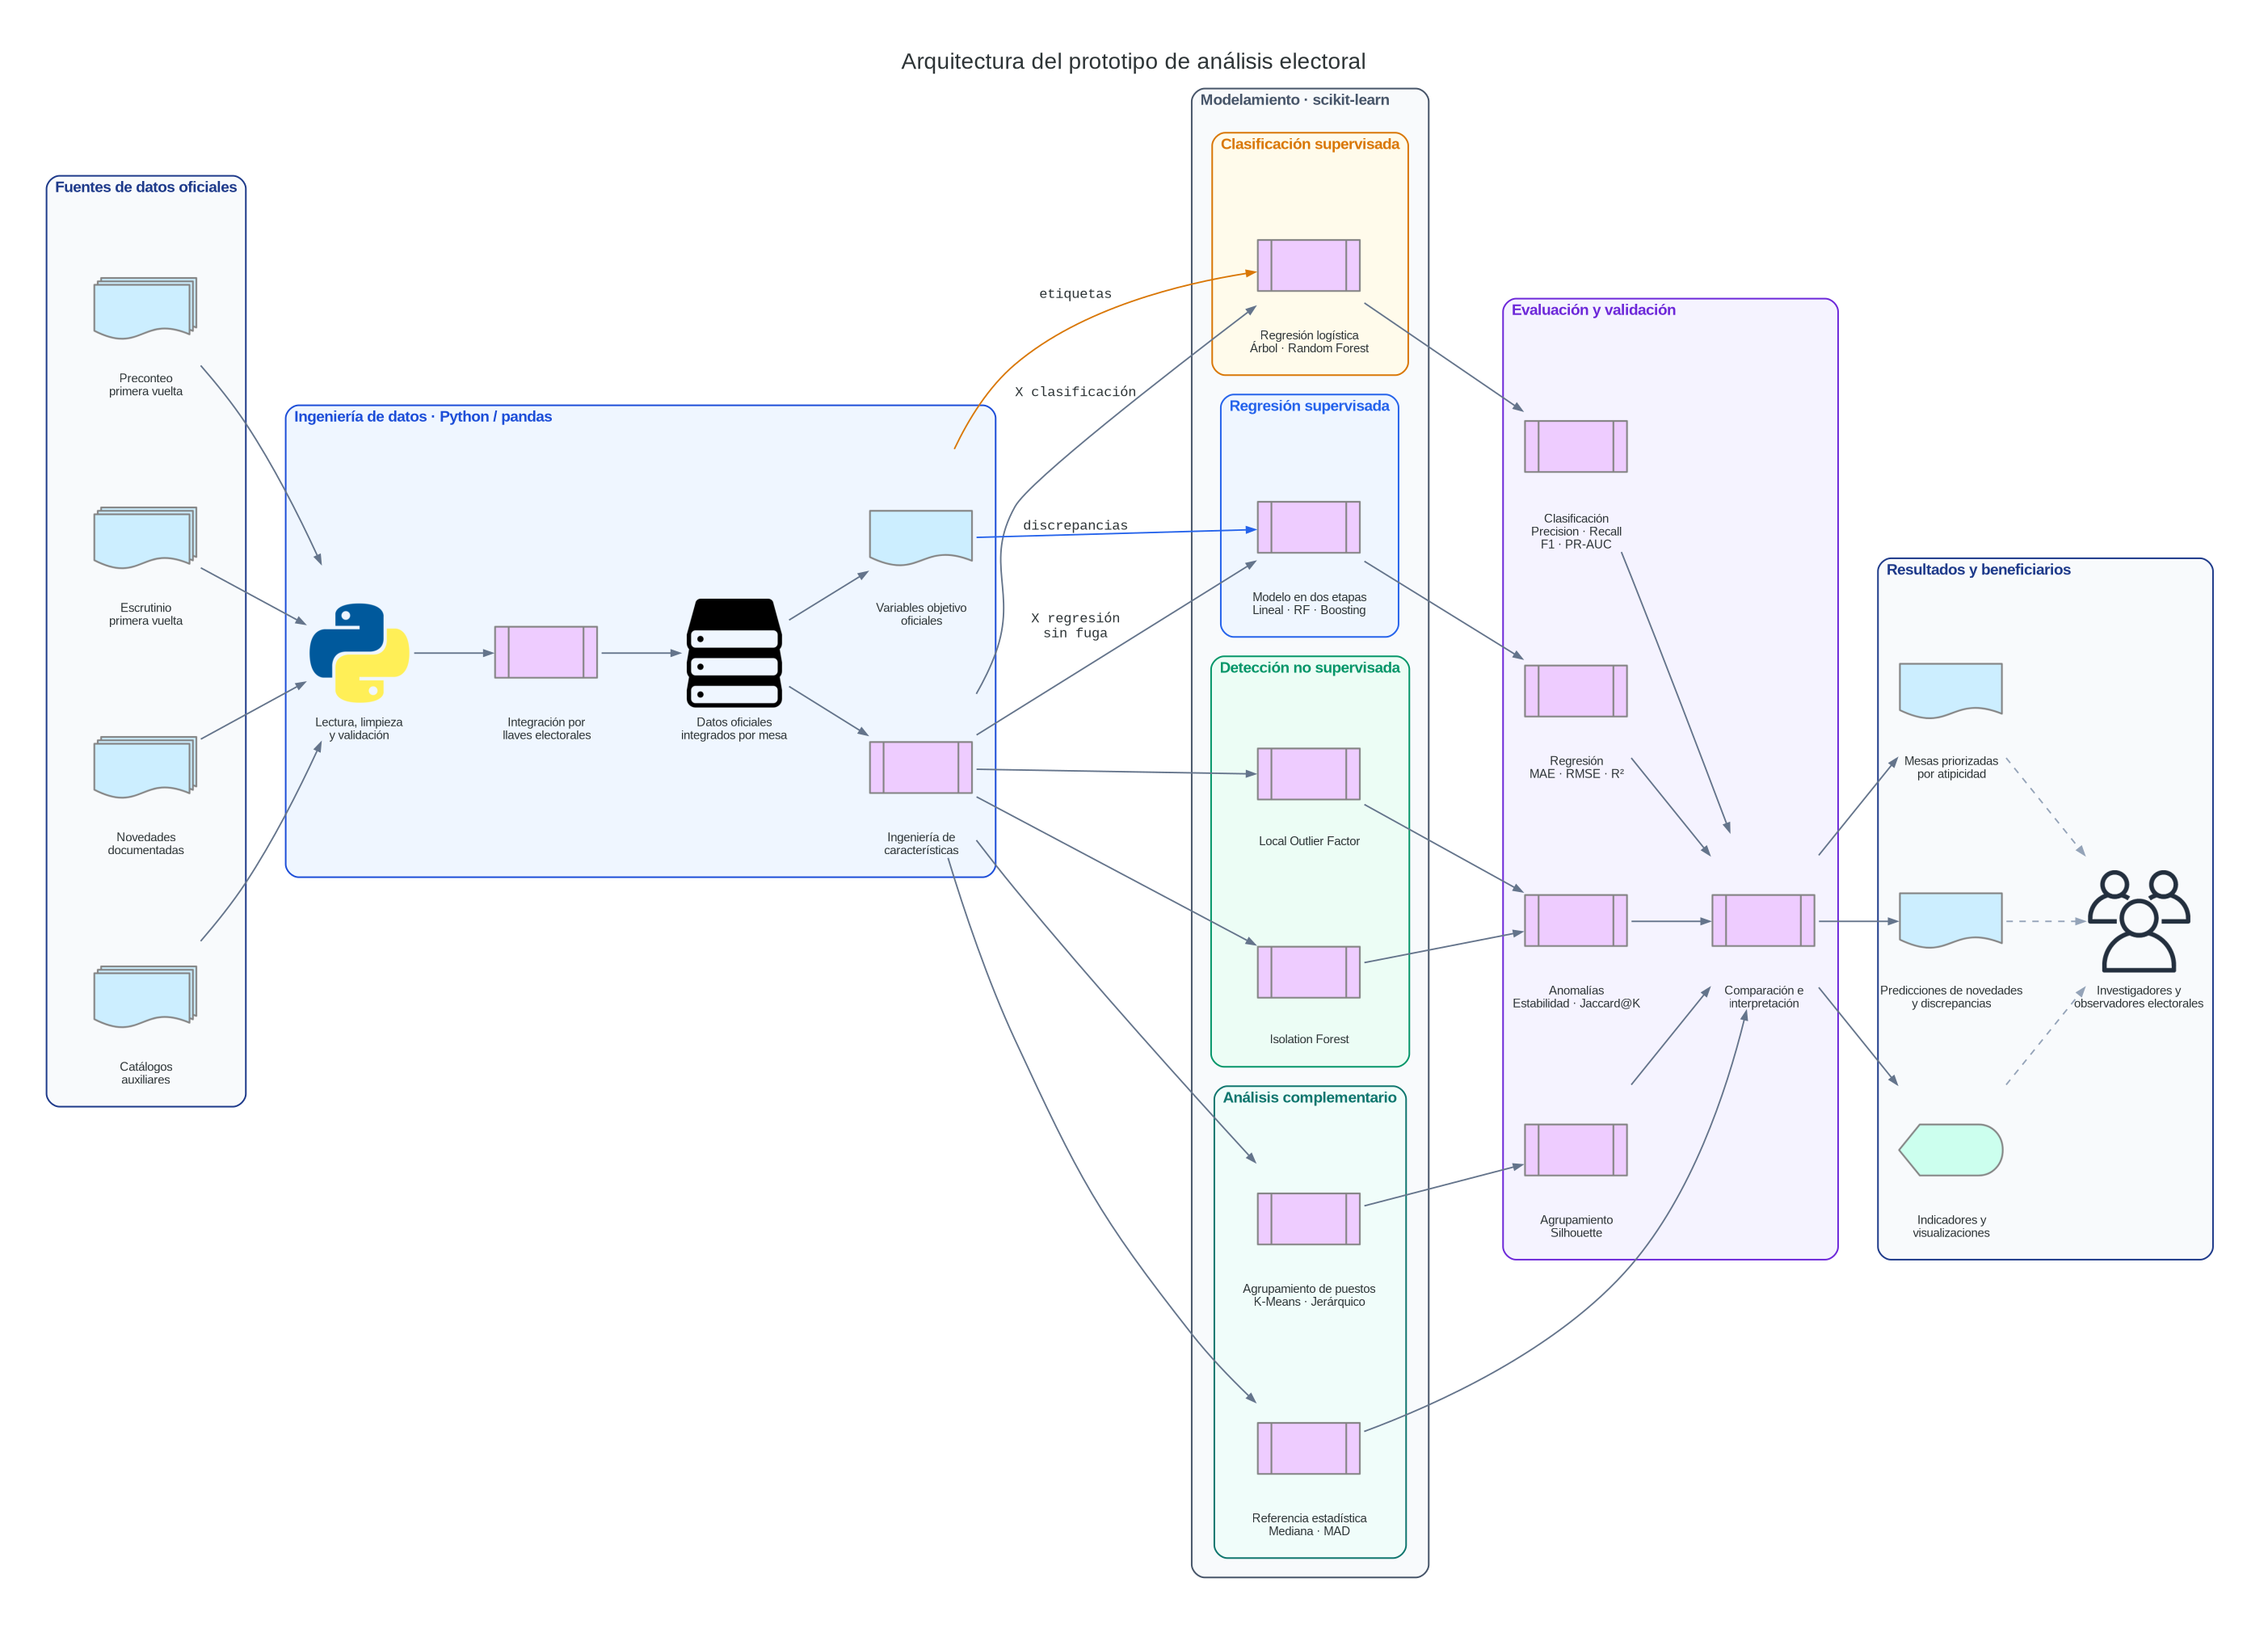

In [ ]:

from diagrams import Diagram, Cluster, Edge
from diagrams.onprem.client import Users
from diagrams.programming.language import Python
from diagrams.programming.flowchart import (
    MultipleDocuments,
    PredefinedProcess,
    Document,
    Display
)
from diagrams.generic.storage import Storage
from IPython.display import Image, display

# ============================================================
# CONFIGURACIÓN VISUAL
# ============================================================

graph_attr = {
    "fontname": "Helvetica",
    "fontsize": "21",
    "bgcolor": "white",
    "pad": "0.6",
    "nodesep": "0.65",
    "ranksep": "1.0",
    "splines": "spline",
    "labelloc": "t"
}

node_attr = {
    "fontname": "Helvetica",
    "fontsize": "11"
}

edge_attr = {
    "color": "#64748B",
    "penwidth": "1.4",
    "arrowsize": "0.8"
}

def zona(fondo, borde):
    return {
        "bgcolor": fondo,
        "pencolor": borde,
        "penwidth": "1.5",
        "fontname": "Helvetica-Bold",
        "fontsize": "14",
        "fontcolor": borde,
        "style": "rounded",
        "margin": "18"
    }

# ============================================================
# ARQUITECTURA DEL PROTOTIPO
# ============================================================

with Diagram(
    "Arquitectura del prototipo de análisis electoral",
    filename="arquitectura",
    outformat="png",
    show=False,
    direction="LR",
    graph_attr=graph_attr,
    node_attr=node_attr,
    edge_attr=edge_attr
):

    # --------------------------------------------------------
    # 1. FUENTES OFICIALES
    # --------------------------------------------------------

    with Cluster(
        "Fuentes de datos oficiales",
        graph_attr=zona("#F8FAFC", "#1E3A8A")
    ):
        pre = MultipleDocuments(
            "Preconteo\nprimera vuelta"
        )

        esc = MultipleDocuments(
            "Escrutinio\nprimera vuelta"
        )

        nov = MultipleDocuments(
            "Novedades\ndocumentadas"
        )

        cat = MultipleDocuments(
            "Catálogos\nauxiliares"
        )

    # --------------------------------------------------------
    # 2. INGENIERÍA DE DATOS
    # --------------------------------------------------------

    with Cluster(
        "Ingeniería de datos · Python / pandas",
        graph_attr=zona("#EFF6FF", "#1D4ED8")
    ):
        etl = Python(
            "Lectura, limpieza\ny validación"
        )

        join = PredefinedProcess(
            "Integración por\nllaves electorales"
        )

        ds = Storage(
            "Datos oficiales\nintegrados por mesa"
        )

        feat = PredefinedProcess(
            "Ingeniería de\ncaracterísticas"
        )

        objetivos = Document(
            "Variables objetivo\noficiales"
        )

        etl >> join >> ds
        ds >> feat
        ds >> objetivos

    # --------------------------------------------------------
    # 3. MODELAMIENTO
    # --------------------------------------------------------

    with Cluster(
        "Modelamiento · scikit-learn",
        graph_attr=zona("#F8FAFC", "#475569")
    ):

        with Cluster(
            "Clasificación supervisada",
            graph_attr=zona("#FFFBEB", "#D97706")
        ):
            clf = PredefinedProcess(
                "Regresión logística\nÁrbol · Random Forest"
            )

        with Cluster(
            "Regresión supervisada",
            graph_attr=zona("#EFF6FF", "#2563EB")
        ):
            reg = PredefinedProcess(
                "Modelo en dos etapas\nLineal · RF · Boosting"
            )

        with Cluster(
            "Detección no supervisada",
            graph_attr=zona("#ECFDF5", "#059669")
        ):
            iso = PredefinedProcess(
                "Isolation Forest"
            )

            lof = PredefinedProcess(
                "Local Outlier Factor"
            )

        with Cluster(
            "Análisis complementario",
            graph_attr=zona("#F0FDFA", "#0F766E")
        ):
            cluster = PredefinedProcess(
                "Agrupamiento de puestos\nK-Means · Jerárquico"
            )

            base = PredefinedProcess(
                "Referencia estadística\nMediana · MAD"
            )

    # --------------------------------------------------------
    # 4. EVALUACIÓN
    # --------------------------------------------------------

    with Cluster(
        "Evaluación y validación",
        graph_attr=zona("#F5F3FF", "#6D28D9")
    ):
        ev_clf = PredefinedProcess(
            "Clasificación\nPrecision · Recall\nF1 · PR-AUC"
        )

        ev_reg = PredefinedProcess(
            "Regresión\nMAE · RMSE · R²"
        )

        ev_uns = PredefinedProcess(
            "Anomalías\nEstabilidad · Jaccard@K"
        )

        ev_group = PredefinedProcess(
            "Agrupamiento\nSilhouette"
        )

        ev = PredefinedProcess(
            "Comparación e\ninterpretación"
        )

    # --------------------------------------------------------
    # 5. RESULTADOS Y BENEFICIARIOS
    # --------------------------------------------------------

    with Cluster(
        "Resultados y beneficiarios",
        graph_attr=zona("#F8FAFC", "#1E3A8A")
    ):
        rank = Document(
            "Mesas priorizadas\npor atipicidad"
        )

        results = Document(
            "Predicciones de novedades\ny discrepancias"
        )

        viz = Display(
            "Indicadores y\nvisualizaciones"
        )

        user = Users(
            "Investigadores y\nobservadores electorales"
        )

    # ========================================================
    # CONEXIONES
    # ========================================================

    # Fuentes -> ingeniería
    for fuente in [pre, esc, nov, cat]:
        fuente >> etl

    # Objetivos supervisados:
    # etiquetas de novedades y discrepancias observadas
    objetivos >> Edge(
        label="etiquetas",
        color="#D97706"
    ) >> clf

    objetivos >> Edge(
        label="discrepancias",
        color="#2563EB"
    ) >> reg

    # Características específicas para cada tarea.
    # En regresión se excluyen variables que revelen
    # directamente la discrepancia objetivo.

    feat >> Edge(
        label="X clasificación"
    ) >> clf

    feat >> Edge(
        label="X regresión\nsin fuga"
    ) >> reg

    feat >> [iso, lof, cluster, base]

    # Modelos -> evaluación
    clf >> ev_clf
    reg >> ev_reg

    iso >> ev_uns
    lof >> ev_uns

    cluster >> ev_group

    # Evaluación integrada
    for evaluacion in [
        ev_clf, ev_reg, ev_uns, ev_group, base
    ]:
        evaluacion >> ev

    # Resultados
    ev >> [rank, results, viz]

    # Revisión humana
    for salida in [rank, results, viz]:
        salida >> Edge(
            style="dashed",
            color="#94A3B8"
        ) >> user

display(Image(filename="arquitectura.png"))


**Figura 2.** *Arquitectura técnica del prototipo de análisis electoral mediante aprendizaje automático (elaboración propia).*

La Figura 2 presenta la integración de registros electorales oficiales, su procesamiento y la construcción de variables para los componentes supervisados y no supervisados. Las variables objetivo se obtienen de novedades documentadas y discrepancias observadas, mientras que las características de entrada se seleccionan según cada tarea para evitar fugas de información. Los resultados se someten a evaluación y comparación antes de generar predicciones, indicadores y listados de observaciones priorizadas para su interpretación por parte de los beneficiarios.

#### ¿Cuáles son los límites y fronteras del proyecto de *machine learning*? ¿Qué aspectos específicos del negocio se incluirán y cuáles se excluyen?

El proyecto se delimita al **análisis retrospectivo de los registros oficiales de la primera vuelta presidencial de Colombia de 2026**, utilizando como unidad principal de análisis la mesa de votación y, de manera complementaria, el puesto electoral. Su alcance comprende la preparación de información, el análisis exploratorio, el desarrollo de modelos de aprendizaje automático y la evaluación de sus resultados.

La delimitación de los aspectos incluidos y excluidos se presenta a continuación.

| Dimensión | Incluido en el alcance | Excluido del alcance |
|---|---|---|
| **Información** | Registros oficiales de preconteo, escrutinio, novedades electorales y catálogos auxiliares. | Datos sintéticos, etiquetas simuladas e información personal de votantes. |
| **Cobertura** | Primera vuelta presidencial de Colombia de 2026, con análisis por mesa, puesto y agrupaciones territoriales. | Predicción de elecciones futuras y generalización automática a otros procesos electorales. |
| **Preparación de datos** | Validación de fuentes, integración de registros, limpieza, análisis descriptivo e ingeniería de características. | Modificación artificial de resultados electorales para generar escenarios hipotéticos. |
| **Clasificación supervisada** | Predicción de novedades administrativas documentadas mediante etiquetas oficiales. | Clasificación de mesas como fraudulentas o legítimas. |
| **Regresión supervisada** | Estimación de la magnitud de las discrepancias entre preconteo y escrutinio. | Determinación de las causas de las discrepancias o de una posible manipulación electoral. |
| **Análisis no supervisado** | Identificación de patrones atípicos y agrupamiento exploratorio de perfiles electorales. | Interpretación automática de anomalías como irregularidades demostradas. |
| **Evaluación** | Métricas específicas por tarea, comparación con referencias estadísticas y validación agrupada territorialmente. | Certificación institucional o jurídica de los resultados. |
| **Producto** | Notebook reproducible en Google Colab, con indicadores, visualizaciones, resultados y documentación metodológica. | Plataforma institucional de auditoría en tiempo real o sistema automático de decisiones. |

**Condiciones y limitaciones metodológicas**

La viabilidad de los componentes supervisados dependerá de la disponibilidad, integridad y correspondencia de los registros oficiales. La clasificación requerirá etiquetas administrativas válidas, mientras que la regresión exigirá un emparejamiento confiable entre preconteo y escrutinio. Se establecerán variables de entrada específicas para cada tarea con el fin de evitar fugas de información desde las variables objetivo.

La evaluación contemplará métricas como precisión, sensibilidad, F1 y PR-AUC para clasificación; MAE, RMSE y R² para regresión; y estabilidad, concordancia entre métodos y Jaccard@K para los análisis no supervisados. Cuando corresponda, se utilizarán particiones agrupadas por departamento para examinar la capacidad de generalización territorial.

Finalmente, **una novedad administrativa, una discrepancia entre registros y una anomalía estadística representan fenómenos diferentes y ninguno constituye, por sí mismo, evidencia de fraude electoral**. Los resultados tendrán carácter exploratorio y deberán interpretarse considerando el contexto y la documentación disponible (Chandola et al., 2009).

#### ¿De qué forma el cliente o beneficiario utilizará el producto del proyecto?

Los usuarios potenciales de la solución son los auditores de sistemas que acredita la Registraduría Nacional del Estado Civil, que son el público al que está dirigido el paquete *Archivos Básicos para Auditores*. Al tratarse de un proyecto académico, no existe un acuerdo formal con la entidad: el prototipo se plantea como una herramienta que estos usuarios, así como el Consejo Nacional Electoral, los testigos de los partidos y organizaciones de observación como la MOE, podrían utilizar para priorizar la revisión de mesas.

El producto consistirá en un **Jupyter Notebook reproducible en Google Colab**, que permitirá ejecutar el procesamiento de registros oficiales, consultar indicadores electorales y examinar los resultados de los modelos desarrollados.

El proceso de utilización comprenderá seis actividades:

1. **Carga y preparación de información:** incorporar los archivos electorales oficiales y ejecutar los procedimientos de lectura, validación e integración de registros.

2. **Exploración de indicadores:** consultar estadísticas descriptivas y visualizaciones de participación, distribución de votos, concentración electoral y consistencia entre fuentes.

3. **Consulta de resultados:** examinar las predicciones de novedades administrativas, las estimaciones de discrepancias y las puntuaciones de atipicidad generadas por los modelos.

4. **Priorización de registros:** identificar mesas que ameriten una revisión adicional a partir de indicadores, resultados de los modelos y criterios de priorización documentados.

5. **Contraste documental:** revisar las observaciones seleccionadas frente a los registros oficiales disponibles, considerando su contexto territorial y administrativo.

6. **Documentación de hallazgos:** registrar las observaciones, posibles explicaciones y limitaciones del análisis para facilitar su interpretación y reproducción.

La **Figura 1** presenta esta secuencia de utilización, desde la ejecución del prototipo hasta la documentación de los hallazgos.

**Figura 1.** *Secuencia de uso previsto del prototipo por beneficiarios potenciales (elaboración propia).*

El valor del producto radica en facilitar el análisis reproducible de información electoral y apoyar la selección de registros para revisión estadística o documental. Su utilización estará orientada a la exploración y el análisis académico, sin reemplazar los procedimientos oficiales de las autoridades electorales.

In [ ]:

mermaid("""
%%{init: {
  "theme": "base",
  "flowchart": {
    "curve": "basis",
    "nodeSpacing": 40,
    "rankSpacing": 65,
    "padding": 20,
    "htmlLabels": true
  },
  "themeVariables": {
    "fontFamily": "Helvetica, Arial, sans-serif",
    "fontSize": "14px",
    "lineColor": "#94A3B8",
    "primaryBorderColor": "#CBD5E1",
    "clusterBkg": "#F8FAFC",
    "clusterBorder": "#E2E8F0"
  }
}}%%

flowchart LR

    %% ============================
    %% FUENTES Y PREPROCESAMIENTO
    %% ============================

    A["Datos electorales oficiales<br/>Preconteo · Escrutinio · Novedades<br/>Primera vuelta presidencial 2026"]

    B["Integración y<br/>validación de datos"]

    C["Análisis exploratorio e<br/>ingeniería de características"]

    %% ============================
    %% MODELOS DE MACHINE LEARNING
    %% ============================

    D["Aprendizaje no supervisado<br/>Isolation Forest · LOF"]

    E["Clasificación supervisada<br/>Regresión logística · Random Forest"]

    H["Regresión supervisada<br/>Discrepancias preconteo–escrutinio"]

    %% ============================
    %% EVALUACIÓN Y RESULTADOS
    %% ============================

    F["Evaluación y comparación<br/>con métodos estadísticos"]

    G["Visualización de resultados<br/>Indicadores · Registros priorizados"]

    %% ============================
    %% FLUJO PRINCIPAL
    %% ============================

    A --> B --> C

    C --> D
    C --> E
    C --> H

    D --> F
    E --> F
    H --> F

    F --> G

    %% ============================
    %% SISTEMA DE DISEÑO
    %% ============================

    classDef data fill:#EFF6FF,stroke:#3B82F6,stroke-width:1.5px,color:#1E40AF

    classDef finding fill:#FEF3C7,stroke:#D97706,stroke-width:2px,color:#92400E

    classDef decision fill:#FFF7ED,stroke:#F59E0B,stroke-width:1.5px,color:#92400E

    classDef alternative fill:#F8FAFC,stroke:#CBD5E1,stroke-width:1.2px,color:#334155

    classDef validation fill:#ECFDF5,stroke:#10B981,stroke-width:1.5px,color:#065F46

    classDef warning fill:#FFF1F2,stroke:#E11D48,stroke-width:2px,color:#9F1239

    %% ============================
    %% ASIGNACIÓN DE ESTILOS
    %% ============================

    class A data
    class B,C validation
    class D,E,H alternative
    class F finding
    class G data

    %% ============================
    %% CONECTORES
    %% ============================

    linkStyle default stroke:#94A3B8,stroke-width:1.5px
""")


### **1.3. Plan**
---

Puede agregar una lista de actividades con tiempos estimados, un diagrama de Gantt o integrar alguna herramienta de gestión de proyectos para mostrar la planeación del proyecto como [*Jira*](https://www.atlassian.com/software/jira?&aceid=&adposition=&adgroup=144583570757&campaign=19313283508&creative=641924587890&device=c&keyword=jira%20software%20online&matchtype=p&network=g&placement=&ds_kids=p74602877891&ds_e=GOOGLE&ds_eid=700000001558501&ds_e1=GOOGLE&gad_source=1&gclid=CjwKCAiAqNSsBhAvEiwAn_tmxStBdySS6RxbLNGXE0tWTeJc32ffjQD_1EXZvH6hmQkYZm5bTa3sgBoCX3oQAvD_BwE&gclsrc=aw.ds) o [*Trello*](https://trello.com/?&aceid=&adposition=&adgroup=144675712219&campaign=19250238609&creative=641300630637&device=c&keyword=trello&matchtype=e&network=g&placement=&ds_kids=p74526213668&ds_e=GOOGLE&ds_eid=700000001557344&ds_e1=GOOGLE&gad_source=1&gclid=CjwKCAiAqNSsBhAvEiwAn_tmxWW7Gdzf0Szf-mA-piM2GPM7tk8R0HsgpBALLGHNFq1-2xXMQbxB1RoCs-sQAvD_BwE&gclsrc=aw.ds).

**Cronograma detallado (fechas y responsables por actividad):**



| ID | Fase | Actividad | Subactividad | Responsable | Apoyo | Inicio | Fin | Duración (días) | Estado | Entregable |
|---|---|---|---|---|---|---|---|---|---|---|
| 1 | Fase 1 · Negocio y carga | Objetivos del negocio | Trasfondo del problema de auditoría electoral; beneficiarios: Registraduría, auditores acreditados, CNE y MOE | Todos |  | 10 oct | 12 oct | 3 | Pendiente | Notebook Fase 1 |
| 2 | Fase 1 · Negocio y carga | Metas del proyecto de ML | Traducir el objetivo de negocio a tareas de ML: clasificar novedades, regresar la discrepancia y detectar mesas atípicas | Alejandra | Todos | 11 oct | 12 oct | 2 | Pendiente | Notebook Fase 1 |
| 3 | Fase 1 · Negocio y carga | Planeación | Cronograma por fases, responsables, riesgos y criterios de éxito | Alejandra | Todos | 11 oct | 13 oct | 3 | Pendiente | Plan de proyecto |
| 4 | Fase 1 · Negocio y carga | Recolección inicial de datos | Inventariar el paquete de auditores: tamaños, formatos, codificación latin-1 y licencia de uso | Brayan | Santiago | 10 oct | 12 oct | 3 | Pendiente | Inventario de fuentes |
| 5 | Fase 1 · Negocio y carga | Código de carga — MMV | Lectura del preconteo (ancho fijo, 38 caracteres) y del escrutinio (delimitado por ;) según Estructuras Básicas | Alejandra | Brayan | 11 oct | 13 oct | 3 | Pendiente | Script de carga |
| 6 | Fase 1 · Negocio y carga | Código de carga — catálogos y novedades | Lectura de PARTIDOS, CANDIDATOS, DIVIPOL y del CSV de novedades, tolerando líneas malformadas | Brayan | Alejandra | 12 oct | 13 oct | 2 | Pendiente | Script de carga |
| 7 | Fase 1 · Negocio y carga | Verificación del cruce | Emparejamiento mesa a mesa entre las tres fuentes; normalizar zona (zfill 3) y partido (zfill 5) | Alejandra | Santiago | 13 oct | 14 oct | 2 | Pendiente | Reporte de llaves |
| 8 | Fase 1 · Negocio y carga | **ENTREGA FASE 1** | Notebook con el código de carga ejecutándose de principio a fin | Todos |  | 13 oct | 14 oct | 2 | Pendiente | ★ miércoles 14 oct |
| 9 | Fase 2 · Entendimiento de datos | Autenticación de fuentes | Verificar los hashes MD5 y SHA1 publicados por la Registraduría y documentar la trazabilidad | Brayan | Alejandra | 15 oct | 16 oct | 2 | Pendiente | Evidencia de autenticidad |
| 10 | Fase 2 · Entendimiento de datos | Diccionario de datos | Documentar cada variable, tipo, dominio y justificación; mapear códigos de partido, candidato y los especiales 996, 997 y 998 | Brayan | Santiago | 15 oct | 17 oct | 3 | Pendiente | Diccionario de datos |
| 11 | Fase 2 · Entendimiento de datos | Verificación de calidad | Duplicados, faltantes, rangos imposibles, líneas malformadas y filas omitidas del preconteo (ausencia = cero) | Brayan | Alejandra | 16 oct | 18 oct | 3 | Pendiente | Informe de calidad |
| 12 | Fase 2 · Entendimiento de datos | Análisis descriptivo | Tendencia central y dispersión de votos, participación, concentración y discrepancias, por departamento y tipo de puesto | Alejandra | Brayan | 16 oct | 19 oct | 4 | Pendiente | Notebook Fase 2 |
| 13 | Fase 2 · Entendimiento de datos | Análisis exploratorio | Distribuciones, valores extremos, relaciones entre variables y comparación entre grupos territoriales | Santiago | Alejandra | 17 oct | 20 oct | 4 | Pendiente | Notebook Fase 2 |
| 14 | Fase 2 · Entendimiento de datos | Efecto de candidatos retirados | Cuantificar la anulación de los candidatos 009 y 013 y su impacto sobre la medición de discrepancias | Alejandra | Todos | 17 oct | 19 oct | 3 | Pendiente | Hallazgo documentado |
| 15 | Fase 2 · Entendimiento de datos | Visualización de los datos | Gráficos que ilustren distribuciones, heterogeneidad territorial y contrastes de consistencia | Santiago | Brayan | 18 oct | 21 oct | 4 | Pendiente | Producto visual |
| 16 | Fase 2 · Entendimiento de datos | **ENTREGA FASE 2** | Notebook de entendimiento de los datos | Todos |  | 20 oct | 21 oct | 2 | Pendiente | ★ miércoles 21 oct |
| 17 | Fase 3 · Preparación de datos | Limpieza del conjunto | Corregir codificación, normalizar llaves, resolver duplicados y documentar cada decisión de limpieza | Brayan | Alejandra | 22 oct | 24 oct | 3 | Pendiente | Datos limpios |
| 18 | Fase 3 · Preparación de datos | Tabla analítica por mesa | Agregar de formato largo a una fila por mesa, conservando las llaves electorales | Alejandra | Brayan | 22 oct | 24 oct | 3 | Pendiente | Dataset por mesa |
| 19 | Fase 3 · Preparación de datos | Ingeniería de variables | Participación, HHI, concentración, tasas de blanco, nulo y no marcado, candidaturas con voto y tamaño de mesa y puesto | Santiago | Alejandra | 23 oct | 26 oct | 4 | Pendiente | Variables documentadas |
| 20 | Fase 3 · Preparación de datos | Variables de consistencia | Contrastes forenses: votosUrna menos totalVotos, sufragantes E11 menos E14, exceso sobre potencial y firmas de jurados | Brayan | Santiago | 23 oct | 26 oct | 4 | Pendiente | Indicadores de consistencia |
| 21 | Fase 3 · Preparación de datos | Construcción de etiquetas | Etiqueta combinada de novedad documentada y variable continua de discrepancia preconteo–escrutinio | Alejandra | Brayan | 24 oct | 26 oct | 3 | Pendiente | Variables objetivo |
| 22 | Fase 3 · Preparación de datos | Preprocesamiento y transformación | Escalado, codificación de categóricas, tratamiento de faltantes y de valores extremos; justificar cada transformación | Santiago | Brayan | 25 oct | 27 oct | 3 | Pendiente | Pipeline de preprocesamiento |
| 23 | Fase 3 · Preparación de datos | Partición del conjunto de datos | Definir y justificar la partición agrupada por departamento, evitando que mesas del mismo territorio caigan en ambos lados | Alejandra | Todos | 26 oct | 27 oct | 2 | Pendiente | Particiones documentadas |
| 24 | Fase 3 · Preparación de datos | **ENTREGA FASE 3** | Notebook de preparación de los datos con el dataset final justificado | Todos |  | 27 oct | 28 oct | 2 | Pendiente | ★ miércoles 28 oct |
| 25 | Fase 4 · Modelamiento y validación | Variables de entrada y salida | Documentar explícitamente qué entra a cada modelo y qué predice, y verificar que no haya fuga de información | Alejandra | Brayan | 29 oct | 30 oct | 2 | Pendiente | Especificación de variables |
| 26 | Fase 4 · Modelamiento y validación | Diseño de la experimentación | Validación cruzada agrupada por departamento y protocolo de comparación entre modelos | Alejandra | Todos | 29 oct | 30 oct | 2 | Pendiente | Protocolo de validación |
| 27 | Fase 4 · Modelamiento y validación | Definición de métricas | Precision, recall, F1 y PR-AUC para clasificación; MAE, RMSE y R² para regresión; Jaccard@K y estabilidad para lo no supervisado | Todos |  | 29 oct | 30 oct | 2 | Pendiente | Criterios de evaluación |
| 28 | Fase 4 · Modelamiento y validación | Justificación de los modelos | Argumentar por qué cada algoritmo corresponde al problema, supervisado y no supervisado | Todos |  | 30 oct | 31 oct | 2 | Pendiente | Justificación metodológica |
| 29 | Fase 4 · Modelamiento y validación | Clasificación supervisada | Regresión logística, árbol de decisión y Random Forest sobre la etiqueta documentada, con pesos de clase | Alejandra | Brayan | 30 oct | 2 nov | 4 | Pendiente | Modelos de clasificación |
| 30 | Fase 4 · Modelamiento y validación | Regresión de la discrepancia | Modelo en dos etapas sobre el objetivo inflado en cero; lineal, Random Forest y Gradient Boosting | Brayan | Alejandra | 30 oct | 2 nov | 4 | Pendiente | Modelos de regresión |
| 31 | Fase 4 · Modelamiento y validación | Referencia estadística | Puntuaciones robustas con mediana y MAD dentro de grupos territoriales comparables | Brayan | Santiago | 29 oct | 31 oct | 3 | Pendiente | Baseline estadístico |
| 32 | Fase 4 · Modelamiento y validación | Isolation Forest y LOF | Entrenar sin usar las etiquetas; n_estimators=200 y n_neighbors=20 como punto de partida | Santiago | Brayan | 30 oct | 2 nov | 4 | Pendiente | Puntajes de atipicidad |
| 33 | Fase 4 · Modelamiento y validación | Agrupamiento de puestos | K-Means y jerárquico sobre perfiles agregados por puesto, evaluados con silhouette | Santiago | Alejandra | 1 nov | 2 nov | 2 | Pendiente | Perfiles de puestos |
| 34 | Fase 4 · Modelamiento y validación | Bitácora de experimentos | Registrar cada configuración, sus hiperparámetros y su resultado, para evidenciar experimentación extensiva | Santiago | Todos | 30 oct | 2 nov | 4 | Pendiente | Bitácora de experimentos |
| 35 | Fase 4 · Modelamiento y validación | **ENTREGA FASE 4** | Notebook de modelamiento y validación | Todos |  | 3 nov | 4 nov | 2 | Pendiente | ★ miércoles 4 nov |
| 36 | Fase 5 · Evaluación y entrega | Análisis de las métricas | Comparar todos los modelos contra la línea base; reportar precision@K y curva de ganancia además de las métricas globales | Alejandra | Brayan | 2 nov | 4 nov | 3 | Pendiente | Tabla de métricas |
| 37 | Fase 5 · Evaluación y entrega | Validación externa del detector | Contrastar el ranking no supervisado contra las novedades documentadas que el modelo nunca vio | Alejandra | Todos | 3 nov | 5 nov | 3 | Pendiente | Evidencia de validación |
| 38 | Fase 5 · Evaluación y entrega | Sensibilidad y estabilidad | Jaccard@K entre métodos, variación de parámetros y perturbaciones controladas para medir el piso de detección | Brayan | Santiago | 3 nov | 5 nov | 3 | Pendiente | Análisis de sensibilidad |
| 39 | Fase 5 · Evaluación y entrega | Análisis de los resultados | Importancia de variables, revisión contextual de mesas señaladas e interpretación de cada hallazgo | Todos |  | 4 nov | 5 nov | 2 | Pendiente | Interpretación documentada |
| 40 | Fase 5 · Evaluación y entrega | Impacto sobre los objetivos de negocio | Responder si los resultados sirven para priorizar revisión y qué le aportan a la Registraduría y a los auditores | Todos |  | 4 nov | 5 nov | 2 | Pendiente | Sección de impacto |
| 41 | Fase 5 · Evaluación y entrega | Integración del notebook final | Consolidar las cinco secciones en un notebook único que corra de principio a fin, con limitaciones y trabajo futuro | Alejandra | Brayan | 3 nov | 6 nov | 4 | Pendiente | Notebook final .ipynb |
| 42 | Fase 5 · Evaluación y entrega | Guion del video | Guion con tiempos para 5 minutos: preprocesamiento, selección de modelos y evaluación con scikit-learn; repartir secciones | Santiago | Todos | 1 nov | 3 nov | 3 | Pendiente | Guion con tiempos |
| 43 | Fase 5 · Evaluación y entrega | Grabación y edición del video | Grabar, editar y revisar audio, imagen y duración; exportar en .mp4 de máximo 5 minutos | Santiago | Todos | 4 nov | 6 nov | 3 | Pendiente | Video .mp4 |
| 44 | Fase 5 · Evaluación y entrega | Revisión ortográfica y de redacción | Revisar notebook y video completos: ortografía, gramática y coherencia | Brayan | Todos | 5 nov | 6 nov | 2 | Pendiente | Revisión de estilo |
| 45 | Fase 5 · Evaluación y entrega | Ensayo de la presentación | Preparar y ensayar la sustentación para la tutoría sincrónica; repartir las secciones entre los tres | Todos |  | 4 nov | 6 nov | 3 | Pendiente | Presentación lista |
| 46 | Fase 5 · Evaluación y entrega | **SOCIALIZACIÓN** | Sustentar el proyecto en la tutoría sincrónica del sábado 7 de noviembre | Todos |  | 7 nov | 7 nov | 1 | Pendiente | ◆ sábado 7 nov · presentación |
| 47 | Fase 5 · Evaluación y entrega | **ENTREGA FINAL** | Ajustes posteriores a la sustentación y subida del notebook .ipynb y el video .mp4 a la plataforma | Todos |  | 8 nov | 9 nov | 2 | Pendiente | ◆ lunes 9 nov · 23:59 |

*(El diagrama de Gantt correspondiente a este cronograma se muestra a continuación como resumen visual; el detalle completo, día a día, está disponible en el archivo Excel del plan del proyecto.)*

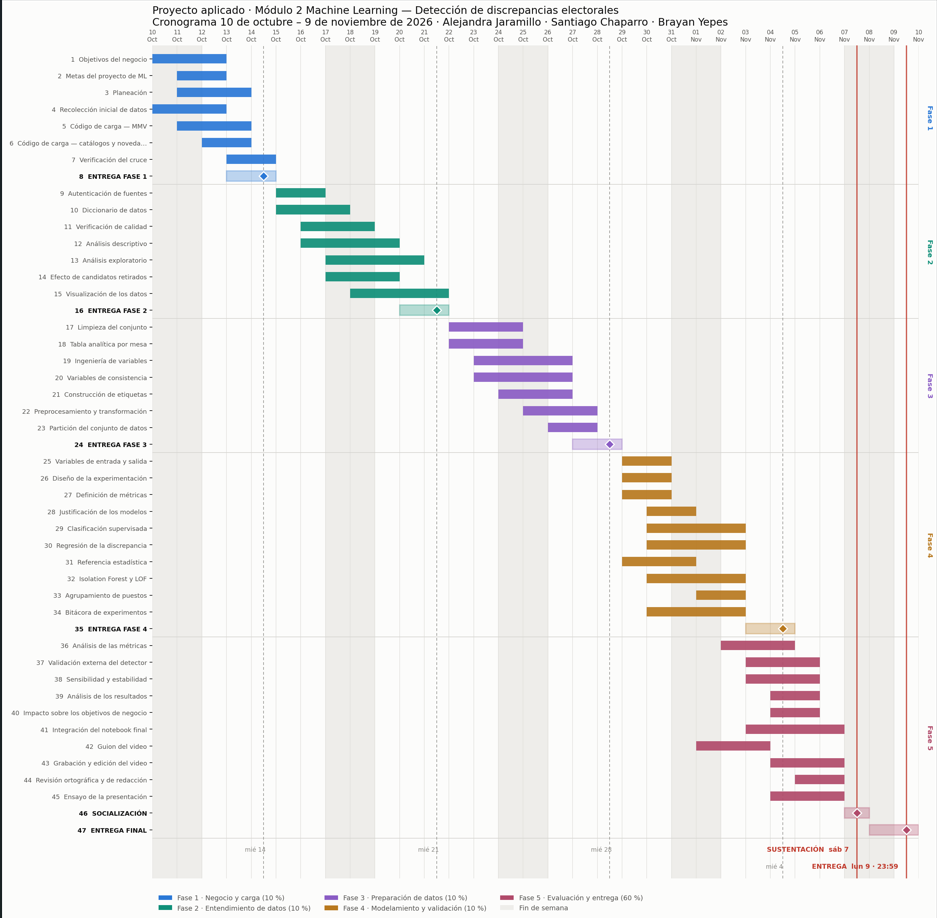

## **2. Datos**
---

En esta sección debe adjuntar una descripción de los datos y agregar el código que permite su tratamiento.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### **2.1. Origen**
---

- ¿De dónde vienen los datos?
- ¿Se usa alguna herramienta o proceso para la descarga de la información?
- ¿Qué tipo de datos estamos manejando?

### **2.1. Origen**
---

#### ¿De dónde vienen los datos?

Los datos son de la **Registraduría Nacional del Estado Civil (RNEC)** y corresponden a la **primera vuelta presidencial del 31 de mayo de 2026**. Forman parte del paquete que la RNEC pone a disposición de los auditores electorales para verificar los resultados de forma independiente.

Un archivo **MMV (*Mesa a Mesa con Votos*)** registra los votos de cada candidatura en cada mesa de votación del país. Es el nivel más desagregado de resultados que publica la RNEC. El proyecto usa estos archivos:

| Archivo | Contenido | Registros |
|---|---|---|
| `PRE1v_MMV_9999_PRECONTEO.txt` | MMV del **preconteo**: conteo rápido de la noche electoral | 1 479 506 |
| `_ficheros_MMV_4_MMV_9999_ESCRUTINIO.csv` | MMV del **escrutinio**: conteo oficial con validez jurídica | 1 952 320 |
| `Novedad20260603.csv` | Novedades por mesa: reconteos, tachaduras, estado del sobre, mesas excluidas, votos en urna, E-11 y E-14 | 118 350 |
| `ARCHIVOSBASICOS_..._V3.zip` | Catálogos de puestos (`DIVIPOL`), candidatos, partidos y tipos de puesto | — |
| `Estructuras_Basicas_1808.pdf` | Diccionario oficial de campos | — |

#### ¿Se usa alguna herramienta o proceso para la descarga de la información?

No se usa una API ni *web scraping*. El archivo `MMV_Presidente1V_2026.zip` se descarga manualmente del [Observatorio Electoral de la RNEC](https://observatorio.registraduria.gov.co/views/electoral/historicos-resultados.php). Antes de cargar los datos, su integridad se verifica con las **huellas criptográficas (MD5 y SHA-256)** que publica la RNEC junto con cada archivo.

#### ¿Qué tipo de datos estamos manejando?

Son **datos estructurados y tabulares** de una sola jornada electoral. La **unidad de análisis es la mesa**: 122 020 mesas en total, de las cuales 118 350 tienen registro de novedades. Las 3 670 restantes son del exterior.

- **Categóricos:** códigos de departamento, municipio, zona, puesto, mesa, partido y candidato.
- **Numéricos discretos:** votos, potencial de votantes, sufragantes, votos en urna y votos incinerados.
- **Dicotómicos (SI/NO):** las novedades del escrutinio, que se usarán para construir la etiqueta supervisada.

Los MMV vienen en **formato largo**: una fila por mesa y candidatura, con 16 candidaturas por mesa (13 candidatos más voto en blanco, nulo y no marcado). Los formatos también son distintos: el preconteo es de ancho fijo, el escrutinio está separado por `;` y los catálogos están codificados en latin-1.

### **2.2. Carga o Adquisición de Datos**
---

Agregue el código necesario en _Python_ para obtener o cargar los datos.

Se debe agregar el archivo .zip en el apartado de "Files" de este colab

https://observatorio.registraduria.gov.co/views/electoral/historicos-resultados.php

Primera vuelta 31 de mayo 2026

### **2.2. Carga o Adquisición de Datos**
---

**Antes de ejecutar:** suba `MMV_Presidente1V_2026.zip` al panel *Files* de Colab (`/content`).

El proceso de carga tiene cinco pasos: descomprimir el paquete, verificar las huellas oficiales, leer cada archivo según *Estructuras Básicas*, normalizar las llaves de mesa y comprobar el cruce entre fuentes.

#### 2.2.1. Descompresión

In [ ]:
import hashlib
import zipfile
from pathlib import Path
import pandas as pd

ZIP_ORIGEN = Path("/content/MMV_Presidente1V_2026.zip")
DATA_DIR = Path("/content/datos")
DATA_DIR.mkdir(parents=True, exist_ok=True)

def buscar_archivo(patron: str, directorio: Path = DATA_DIR) -> Path:
    resultados = list(directorio.rglob(patron))
    if not resultados:
        raise FileNotFoundError(f"No se encontró '{patron}' dentro de {directorio}")
    return resultados[0]

if not ZIP_ORIGEN.exists():
    raise FileNotFoundError(f"Suba 'MMV_Presidente1V_2026.zip' a /content")

with zipfile.ZipFile(ZIP_ORIGEN) as z:
    z.extractall(DATA_DIR)
for zip_interno in ["ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3.zip", "Novedad20260603.zip"]:
    with zipfile.ZipFile(buscar_archivo(zip_interno)) as z:
        z.extractall(DATA_DIR)

ARCH_PRECONTEO  = buscar_archivo("PRE1v_MMV_9999_PRECONTEO.txt")
ARCH_ESCRUTINIO = buscar_archivo("_ficheros_MMV_4_MMV_9999_ESCRUTINIO.csv")
ARCH_NOVEDADES  = buscar_archivo("Novedad20260603.csv")
DIR_BASICOS     = buscar_archivo("HASH.txt").parent

#### 2.2.2. Verificación de integridad

Se compara la huella de cada archivo con la publicada por la RNEC. Si alguna no coincide, la ejecución se detiene.

In [ ]:
def calcular_hash(ruta: Path, algoritmo: str = "md5") -> str:
    h = hashlib.new(algoritmo)
    with open(ruta, "rb") as f:
        for bloque in iter(lambda: f.read(1 << 20), b""):
            h.update(bloque)
    return h.hexdigest()

def hashes_rnec(ruta_hash: Path) -> dict:
    """Lee el HASH.txt de los archivos básicos (UTF-16) -> {archivo: md5}."""
    out, nombre = {}, None
    for linea in ruta_hash.read_text(encoding="utf-16").splitlines():
        if ":" not in linea:
            continue
        clave, valor = [s.strip() for s in linea.split(":", 1)]
        if clave == "Filename":
            nombre = valor
        elif clave == "MD5" and nombre:
            out[nombre] = valor.lower()
    return out

# MD5 de los MMV tomados de los archivos HASH_*.txt de la RNEC
MD5_OFICIAL = {
    ARCH_PRECONTEO.name:  "f957d26d6c9ab7eba8e25d14b48047ea",
    ARCH_ESCRUTINIO.name: "08ae9a4affd1f0c7fdab6c90e8ea2805",
}
MD5_OFICIAL.update(hashes_rnec(DIR_BASICOS / "HASH.txt"))

rutas = {ARCH_PRECONTEO.name: ARCH_PRECONTEO, ARCH_ESCRUTINIO.name: ARCH_ESCRUTINIO}
verificacion = [(n, "md5", calcular_hash(rutas.get(n, DIR_BASICOS / n)) == ref)
                for n, ref in MD5_OFICIAL.items()]

sha_ref = buscar_archivo("HuellaHash.txt").read_text().strip().lower()
verificacion.append((ARCH_NOVEDADES.name, "sha256",
                     calcular_hash(ARCH_NOVEDADES, "sha256") == sha_ref))

df_hash = pd.DataFrame(verificacion, columns=["archivo", "algoritmo", "coincide"])
display(df_hash)
assert df_hash["coincide"].all(), "Algún archivo no coincide con la huella publicada"

,archivo,algoritmo,coincide
0,PRE1v_MMV_9999_PRECONTEO.txt,md5,True
1,_ficheros_MMV_4_MMV_9999_ESCRUTINIO.csv,md5,True
2,INDICADORES_20260526_132437_01.TXT,md5,True
3,DIVIPOL_20260526_132437_01.TXT,md5,True
4,CANDIDATOS_20260516_083436_01.TXT,md5,True
5,CIRCUNSCRIPCION_20260516_083436_01.TXT,md5,True
6,CORPORACION_20260516_083436_01.TXT,md5,True
7,PARTIDOS_20260516_083436_01.TXT,md5,True
8,Novedad20260603.csv,sha256,True


#### 2.2.3. Archivos MMV

El preconteo es de ancho fijo (38 caracteres por registro) y el escrutinio está delimitado por `;`. Las llaves se leen como texto para no perder los ceros a la izquierda.

In [ ]:
COLS_PRE   = ["dep", "mun", "zona", "puesto", "mesa", "jal", "comunicado",
              "circ", "partido", "candidato", "votos"]
ANCHOS_PRE = [2, 3, 2, 2, 6, 2, 4, 1, 5, 3, 8]
precon = pd.read_fwf(ARCH_PRECONTEO, widths=ANCHOS_PRE, names=COLS_PRE,
                     dtype=str, encoding="latin-1")
precon["votos"] = precon["votos"].astype("int64")

COLS_ESC = ["comunicado", "dep", "mun", "zona", "puesto", "mesa", "comuna",
            "corporacion", "circ", "partido", "candidato", "votos"]
escru = pd.read_csv(ARCH_ESCRUTINIO, sep=";", header=None, usecols=range(12),
                    names=COLS_ESC, dtype=str, encoding="latin-1")
escru["votos"] = escru["votos"].astype("int64")

display(precon.head(3), escru.head(3))

,dep,mun,zona,puesto,mesa,jal,comunicado,circ,partido,candidato,votos
0,01,001,01,01,000001,00,9999,0,00009,011,27
1,01,001,01,01,000001,00,9999,0,00015,012,5
2,01,001,01,01,000001,00,9999,0,00020,006,1


,comunicado,dep,mun,zona,puesto,mesa,comuna,corporacion,circ,partido,candidato,votos
0,9999,01,001,001,01,000001,00,001,0,0026,001,30
1,9999,01,001,001,01,000001,00,001,0,1004,002,1
2,9999,01,001,001,01,000001,00,001,0,1001,003,0


#### 2.2.4. Novedades

En 45 líneas el nombre del puesto contiene comas sin comillas. El lector une esos campos en vez de descartar las líneas, así que conserva las 118 350 mesas.

In [ ]:
def leer_novedades(ruta: Path) -> pd.DataFrame:
    with open(ruta, encoding="latin-1") as f:
        encabezado = f.readline().rstrip("\r\n").split(",")
        n_campos, i_nombre = len(encabezado), encabezado.index("puestoNombre")
        n_cola = n_campos - i_nombre - 1
        filas, reparadas = [], 0
        for linea in f:
            partes = linea.rstrip("\r\n").split(",")
            if len(partes) > n_campos:
                partes = (partes[:i_nombre]
                          + [",".join(partes[i_nombre:len(partes) - n_cola])]
                          + partes[-n_cola:])
                reparadas += 1
            filas.append(partes)
    print(f"Novedades: {reparadas} líneas reparadas")
    return pd.DataFrame(filas, columns=encabezado)

noved = leer_novedades(ARCH_NOVEDADES)
COLS_NUM_NOV = ["potencial", "sufragantesSegunE11", "firmasJurados", "votosUrna",
                "votosIncinerados", "sufragantesE11SegunE14", "totalVotos"]
noved[COLS_NUM_NOV] = noved[COLS_NUM_NOV].apply(pd.to_numeric, errors="coerce")
noved.head(3)

Novedades: 45 líneas reparadas


,id,departamentoCodigo,departamentoNombre,municipioCodigo,municipioNombre,zonaNombre,puestoCodigo,puestoNombre,mesaNumero,corporacionCodigo,...,estadoSobre,tachadurasEnmendaduras,recontadaJurados,recontadaComision,excluida,firmasJurados,votosUrna,votosIncinerados,sufragantesE11SegunE14,totalVotos
0,010100101011,01,ANTIOQUIA,001,MEDELLIN,01,01,SEC. ESC. LA ESPERANZA No 2,1,001,...,BUENO,NO,NO,NO,NO,6,128,0,128,127
1,010100101012,01,ANTIOQUIA,001,MEDELLIN,01,01,SEC. ESC. LA ESPERANZA No 2,2,001,...,BUENO,NO,NO,NO,NO,6,65,0,65,65
2,010100101013,01,ANTIOQUIA,001,MEDELLIN,01,01,SEC. ESC. LA ESPERANZA No 2,3,001,...,BUENO,NO,NO,NO,NO,6,107,0,107,107


#### 2.2.5. Catálogos y normalización de llaves

Los catálogos son de ancho fijo y están en latin-1. Después de leerlos se igualan las longitudes de las llaves (zona a 3 dígitos, partido a 5, mesa a 6), de modo que todas las fuentes comparten la llave de mesa `dep + mun + zona + puesto + mesa`.

In [ ]:
def leer_catalogo(prefijo: str, anchos, nombres) -> pd.DataFrame:
    ruta = next(DIR_BASICOS.glob(f"{prefijo}_*.TXT"))
    df = pd.read_fwf(ruta, widths=anchos, names=nombres, dtype=str, encoding="latin-1")
    return df.apply(lambda s: s.str.strip())

divipol = leer_catalogo(
    "DIVIPOL", [2, 3, 2, 2, 12, 30, 40, 1, 8, 8, 6, 2, 30],
    ["dep", "mun", "zona", "puesto", "dep_nombre", "mun_nombre", "puesto_nombre",
     "indicador_puesto", "potencial_hombres", "potencial_mujeres", "n_mesas",
     "comuna", "comuna_nombre"])
for c in ["potencial_hombres", "potencial_mujeres", "n_mesas"]:
    divipol[c] = divipol[c].astype("int64")

partidos = leer_catalogo("PARTIDOS", [5, 200], ["partido", "partido_nombre"])
candidatos = leer_catalogo(
    "CANDIDATOS", [3, 1, 2, 3, 2, 5, 3, 1, 50, 50, 15, 1, 2],
    ["corporacion", "circ", "dep", "mun", "comuna", "partido", "candidato",
     "preferente", "nombre", "apellido", "cedula", "genero", "sorteo"])
indicadores = leer_catalogo("INDICADORES", [1, 100, 4],
                            ["indicador_puesto", "descripcion", "potencial_max_mesa"])
ESPECIALES = {"996": "VOTO EN BLANCO", "997": "VOTOS NULOS", "998": "VOTOS NO MARCADOS"}

# Normalización de llaves
LLAVE_MESA = ["dep", "mun", "zona", "puesto", "mesa"]
for df in (precon, escru):
    df["zona"] = df["zona"].str.zfill(3)
    df["partido"] = df["partido"].str.zfill(5)
divipol["zona"] = divipol["zona"].str.zfill(3)

noved = noved.rename(columns={"departamentoCodigo": "dep", "municipioCodigo": "mun",
                              "zonaNombre": "zona", "puestoCodigo": "puesto",
                              "mesaNumero": "mesa"})
noved["zona"] = noved["zona"].str.zfill(3)
noved["mesa"] = noved["mesa"].str.zfill(6)

candidatos[["candidato", "nombre", "apellido", "partido"]]

,candidato,nombre,apellido,partido
0,001,IVÁN,CEPEDA CASTRO,00026
1,002,CLAUDIA,LÓPEZ,01004
2,003,RAÚL SANTIAGO,BOTERO JARAMILLO,01001
3,004,ABELARDO,DE LA ESPRIELLA,01003
4,005,ÓSCAR MAURICIO,LIZCANO ARANGO,03001
5,006,MIGUEL,URIBE LONDOÑO,00020
6,007,SONDRA MACOLLINS,GARVIN PINTO,01002
7,008,ROY LEONARDO,BARRERAS MONTEALEGRE,00022
8,009,CARLOS EDUARDO,CAICEDO OMAR,01006
9,010,GUSTAVO,MATAMOROS CAMACHO,00021


#### 2.2.6. Tipos de datos

Perfil de las columnas de las tres fuentes principales. Las llaves se mantienen como texto para conservar los ceros a la izquierda, y los conteos son enteros.

In [ ]:
def perfil(df: pd.DataFrame, nombre: str) -> pd.DataFrame:
    return pd.DataFrame({
        "fuente": nombre,
        "columna": df.columns,
        "tipo": df.dtypes.astype(str).values,
        "no_nulos": df.notna().sum().values,
        "valores_unicos": df.nunique().values,
        "ejemplo": df.iloc[0].astype(str).values,
    })

tipos = pd.concat([perfil(precon, "preconteo"),
                   perfil(escru, "escrutinio"),
                   perfil(noved, "novedades")], ignore_index=True)
display(tipos)

,fuente,columna,tipo,no_nulos,valores_unicos,ejemplo
0,preconteo,dep,object,1479506,34,01
1,preconteo,mun,object,1479506,309,001
2,preconteo,zona,object,1479506,52,001
3,preconteo,puesto,object,1479506,208,01
4,preconteo,mesa,object,1479506,228,000001
5,preconteo,jal,object,1479506,1,00
6,preconteo,comunicado,object,1479506,1,9999
7,preconteo,circ,object,1479506,1,0
8,preconteo,partido,object,1479506,14,00009
9,preconteo,candidato,object,1479506,16,011


Las llaves electorales (departamento, municipio, zona, puesto y mesa) y los códigos de partido y candidato se conservan como texto (`object`) para no perder los ceros a la izquierda, y todos los conteos de votos y sufragantes quedan como enteros (`int64`). Ninguna columna de las tres fuentes presenta valores nulos. Las seis banderas del archivo de novedades (`enTerminos`, `estadoSobre`, `tachadurasEnmendaduras`, `recontadaJurados`, `recontadaComision` y `excluida`) tienen dos valores posibles, pero están almacenadas como texto; en la fase de preparación se convertirán a variables binarias (0/1) para construir la etiqueta supervisada.

#### 2.2.7. Resumen de la carga

Resultado esperado: 122 020 mesas en el preconteo y en el escrutinio, y 118 350 en novedades, todas presentes en el escrutinio.

In [ ]:
resumen = pd.DataFrame({
    "fuente":   ["preconteo", "escrutinio", "novedades", "divipol", "partidos", "candidatos"],
    "filas":    [len(precon), len(escru), len(noved), len(divipol), len(partidos), len(candidatos)],
    "columnas": [precon.shape[1], escru.shape[1], noved.shape[1], divipol.shape[1],
                 partidos.shape[1], candidatos.shape[1]],
    "mesas":    [precon[LLAVE_MESA].drop_duplicates().shape[0],
                 escru[LLAVE_MESA].drop_duplicates().shape[0],
                 noved[LLAVE_MESA].drop_duplicates().shape[0], None, None, None],
    "votos_totales": [precon["votos"].sum(), escru["votos"].sum(), None, None, None, None],
})
display(resumen)

m_pre = set(map(tuple, precon[LLAVE_MESA].drop_duplicates().values))
m_esc = set(map(tuple, escru[LLAVE_MESA].drop_duplicates().values))
m_nov = set(map(tuple, noved[LLAVE_MESA].drop_duplicates().values))
print(f"Mesas en preconteo ∩ escrutinio: {len(m_pre & m_esc):,}")
print(f"Mesas de novedades en escrutinio: {len(m_nov & m_esc):,} de {len(m_nov):,}")

,fuente,filas,columnas,mesas,votos_totales
0,preconteo,1479506,11,122020.0,23978304.0
1,escrutinio,1952320,12,122020.0,23990635.0
2,novedades,118350,24,118350.0,NaN
3,divipol,14438,13,NaN,NaN
4,partidos,13,2,NaN,NaN
5,candidatos,13,13,NaN,NaN


Mesas en preconteo ∩ escrutinio: 122,020
Mesas de novedades en escrutinio: 118,350 de 118,350


#### 2.2.8. Conclusiones de la carga y observaciones sobre los datos

La carga cumple el resultado esperado: las seis fuentes se leyeron completas, las huellas criptográficas coinciden con las publicadas por la RNEC y las 122 020 mesas del preconteo y del escrutinio se emparejan una a una mediante la llave `dep + mun + zona + puesto + mesa`, al igual que las 118 350 mesas del archivo de novedades. A partir de la carga se identifican las siguientes características de los datos, que se tendrán en cuenta en las fases siguientes:

- **El preconteo omite los registros con cero votos.** El escrutinio tiene exactamente 16 filas por mesa (122 020 × 16 = 1 952 320), mientras que el preconteo tiene 1 479 506 porque no incluye las combinaciones mesa–candidatura sin votos. Para comparar ambas fuentes, la ausencia de un registro en el preconteo se interpretará como cero votos.
- **Los totales de ambas fuentes difieren.** El escrutinio suma 23 990 635 votos y el preconteo 23 978 304, una diferencia de 12 331 votos (0.05 %). Esta diferencia agregada es pequeña, pero se distribuye de forma desigual entre mesas y constituye la base de la variable de discrepancia.
- **Candidatos retirados.** Los votos de los candidatos con código 009 y 013 se trasladan al código 998 (votos no marcados) en el escrutinio. Este traslado administrativo no es una corrección de la mesa y se aislará al construir la variable de discrepancia, para no confundirlo con diferencias reales entre preconteo y escrutinio.
- **Cobertura de las novedades.** Las 3 670 mesas del exterior no tienen registro de novedades, por lo que el componente de clasificación se limitará a las 118 350 mesas nacionales.
- **Calidad del archivo de novedades.** 45 líneas tienen comas dentro del nombre del puesto; se repararon sin descartar ninguna mesa. Este archivo no está descrito en el documento *Estructuras Básicas*, por lo que su diccionario de campos se construirá en la Fase 2.

## Referencias bibliográficas


Chandola, V., Banerjee, A., & Kumar, V. (2009). Anomaly detection: A survey. ACM Computing Surveys, 41(3), Article 15. https://doi.org/10.1145/1541880.1541882

Han, S., Hu, X., Huang, H., Jiang, M., & Zhao, Y. (2022). ADBench: Anomaly detection benchmark. Advances in Neural Information Processing Systems, 35. https://papers.neurips.cc/paper_files/paper/2022/hash/cf93972b116ca5268827d575f2cc226b-Abstract-Datasets_and_Benchmarks.html

Zhang, M., Alvarez, R. M., & Levin, I. (2019). Election forensics: Using machine learning and synthetic data for possible election anomaly detection. PLOS ONE, 14(10), Article e0223950. https://doi.org/10.1371/journal.pone.0223950


Constitución Política de Colombia [Const.]. (1991). Artículo 265. https://www.cne.gov.co/leyes-y-actos-legislativos-cne
Registraduría Nacional del Estado Civil. (s. f.). Cartilla de escrutinios. https://www.registraduria.gov.co/IMG/pdf/cartilla_escrutinios.pdf
Registraduría Nacional del Estado Civil. (2026). Estas son las diferencias entre los resultados de la transmisión y el escrutinio oficial. https://wapp.registraduria.gov.co/electoral/2026/presidente-de-la-republica/documentos/narrativas/diferencias_transmision_escrutinio.pdf

## **Créditos**
---

* **Profesor:** [Fabio Augusto Gonzalez](https://dis.unal.edu.co/~fgonza/)
* **Asistente docente :**
  * [Rosa Alejandra Superlano Esquibel](https://www.linkedin.com/in/alejandrasuperlano/).
* **Diseño de imágenes:**
    - [Rosa Alejandra Superlano Esquibel](https://www.linkedin.com/in/alejandrasuperlano/).
* **Coordinador de virtualización:**
    - [Edder Hernández Forero](https://www.linkedin.com/in/edder-hernandez-forero-28aa8b207/).

**Universidad Nacional de Colombia** - *Facultad de Ingeniería*